In [1]:
# ============================================
# 🔧 SETUP ENVIRONMENT
# ============================================
!pip -q install segment-anything timm einops torchvision tqdm

import os, torch
from google.colab import drive

# Mount Google Drive (force to avoid "already mounted" issue)
if not os.path.exists("/content/drive"):
    os.makedirs("/content/drive", exist_ok=True)
drive.mount('/content/drive', force_remount=True)

# Device check
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("💻 Device:", device)


Mounted at /content/drive
💻 Device: cuda


In [2]:
# ============================================
# 📂 PATHS — Update only if your folder names differ
# ============================================
DATASET_BASE = "/content/drive/MyDrive/unet_project/dataset"

IMG_TRAIN = f"{DATASET_BASE}/images/train"
MASK_TRAIN = f"{DATASET_BASE}/masks/train"
IMG_VAL   = f"{DATASET_BASE}/images/val"
MASK_VAL  = f"{DATASET_BASE}/masks/val"

SAVE_DIR = "/content/drive/MyDrive/unet_project/sam_unet_runs"
os.makedirs(SAVE_DIR, exist_ok=True)

for p in [IMG_TRAIN, MASK_TRAIN, IMG_VAL, MASK_VAL]:
    print("✅ Found:", p, "|", os.path.exists(p))


✅ Found: /content/drive/MyDrive/unet_project/dataset/images/train | True
✅ Found: /content/drive/MyDrive/unet_project/dataset/masks/train | True
✅ Found: /content/drive/MyDrive/unet_project/dataset/images/val | True
✅ Found: /content/drive/MyDrive/unet_project/dataset/masks/val | True


In [3]:
# ============================================
# 🧠 LOAD SAM CHECKPOINT
# ============================================
SAM_CKPT = "/content/sam_vit_b.pth"
if not os.path.exists(SAM_CKPT):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O /content/sam_vit_b.pth

print("✅ SAM checkpoint ready:", SAM_CKPT)


✅ SAM checkpoint ready: /content/sam_vit_b.pth


In [4]:
# Step 1: Upload from local system to Colab
from google.colab import files
uploaded = files.upload()  # Choose the file manually




Saving archive (9).zip to archive (9).zip


In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [3]:
import zipfile, os

zip_path = "archive (9).zip"       # 👈 your uploaded file name
extract_local = "/content/dataset" # local fast storage

os.makedirs(extract_local, exist_ok=True)

print("⚡ Extracting ZIP locally (this is fast)...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_local)

print("✅ Extracted locally to:", extract_local)


⚡ Extracting ZIP locally (this is fast)...
✅ Extracted locally to: /content/dataset


In [ ]:
from google.colab import drive
import shutil

drive.mount('/content/drive', force_remount=True)

drive_target = "/content/drive/MyDrive/unet_project/dataset_zip"
shutil.copytree(extract_local, drive_target, dirs_exist_ok=True)

print("✅ Copied to Drive:", drive_target)


Mounted at /content/drive


In [2]:
import os

extract_local = "/content/dataset"

for root, dirs, files in os.walk(extract_local):
    print(f"📂 {root} → {len(files)} files")
    if files:
        print("Example files:", files[:5])
    break


📂 /content/dataset → 0 files


In [ ]:
import shutil, os

source_folder = "/content/dataset"
drive_target = "/content/drive/MyDrive/unet_project/dataset_full"

# copy entire dataset
shutil.copytree(source_folder, drive_target, dirs_exist_ok=True)

print("✅ Entire dataset copied to Drive:", drive_target)


✅ Entire dataset copied to Drive: /content/drive/MyDrive/unet_project/dataset_full


In [ ]:
import os, shutil

# ============================================
# 📂 PATHS
# ============================================
DATASET_BASE = "/content/drive/MyDrive/unet_project/dataset_full"
IMG_DIR = os.path.join(DATASET_BASE, "tissue images")
MASK_DIR = os.path.join(DATASET_BASE, "Annotator 1 (biologist)", "mask binary")

print("✅ Image directory :", IMG_DIR)
print("✅ Mask directory  :", MASK_DIR)

# ============================================
# 🧩 SPLIT DATA
# ============================================
all_imgs = sorted([f for f in os.listdir(IMG_DIR) if f.endswith(('.png', '.jpg', '.tif'))])
split_idx = int(0.8 * len(all_imgs))
train_imgs = all_imgs[:split_idx]
val_imgs = all_imgs[split_idx:]

IMG_TRAIN = os.path.join(DATASET_BASE, "images/train")
IMG_VAL   = os.path.join(DATASET_BASE, "images/val")
MASK_TRAIN = os.path.join(DATASET_BASE, "masks/train")
MASK_VAL   = os.path.join(DATASET_BASE, "masks/val")

for p in [IMG_TRAIN, IMG_VAL, MASK_TRAIN, MASK_VAL]:
    os.makedirs(p, exist_ok=True)

# ============================================
# ⚙️ COPY FUNCTION
# ============================================
def find_mask_for_image(img_name):
    """Try to locate the correct mask file (.png) for each image (.tif/.jpg/.png)."""
    base = os.path.splitext(img_name)[0]  # remove extension
    candidates = [
        f"{base}.png",
        f"{base} (1).png",
        f"{base}.tif",
        f"{base} (1).tif"
    ]
    for c in candidates:
        mask_path = os.path.join(MASK_DIR, c)
        if os.path.exists(mask_path):
            return mask_path
    return None  # mask not found

# ============================================
# 📦 COPY TRAIN AND VAL DATA
# ============================================
missing = []
print(f"📦 Copying {len(train_imgs)} training and {len(val_imgs)} validation images...")

for split, imgs, img_out, mask_out in [
    ("train", train_imgs, IMG_TRAIN, MASK_TRAIN),
    ("val", val_imgs, IMG_VAL, MASK_VAL)
]:
    for img in imgs:
        shutil.copy(os.path.join(IMG_DIR, img), os.path.join(img_out, img))
        mask_path = find_mask_for_image(img)
        if mask_path:
            shutil.copy(mask_path, os.path.join(mask_out, os.path.basename(mask_path)))
        else:
            missing.append(img)

if missing:
    print(f"⚠️ Missing masks for {len(missing)} images:")
    for m in missing:
        print("  -", m)
else:
    print("✅ All masks matched!")

print(f"✅ Data split complete: {len(train_imgs)} train, {len(val_imgs)} val images.")


✅ Image directory : /content/drive/MyDrive/unet_project/dataset_full/tissue images
✅ Mask directory  : /content/drive/MyDrive/unet_project/dataset_full/Annotator 1 (biologist)/mask binary
📦 Copying 24 training and 6 validation images...
✅ All masks matched!
✅ Data split complete: 24 train, 6 val images.


In [ ]:
# ============================================
# 🧠 LOAD SAM ENCODER (ViT-B)
# ============================================
from segment_anything import sam_model_registry
from segment_anything.utils.transforms import ResizeLongestSide

sam = sam_model_registry["vit_b"](checkpoint=SAM_CKPT).to(device)
for p in sam.parameters():
    p.requires_grad = False
sam.eval()
sam_pre = ResizeLongestSide(sam.image_encoder.img_size)

@torch.no_grad()
def sam_embedding_from_rgb(batch_rgb):
    """Generate SAM embeddings for batch of 256x256 images"""
    embs = []
    for img in batch_rgb:
        img = (img.cpu().numpy().transpose(1,2,0)*255).astype(np.uint8)
        img_sam = sam_pre.apply_image(img)
        t = torch.as_tensor(img_sam, device=device).permute(2,0,1).float().unsqueeze(0)
        emb = sam.image_encoder(t)
        embs.append(emb)
    embs = torch.cat(embs, 0)
    embs = torch.nn.functional.interpolate(embs, size=(32,32), mode='bilinear', align_corners=False)
    return embs


In [ ]:
# ============================================
# 🧱 MODEL: U-Net + X-Gated Fusion
# ============================================
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.seq = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.seq(x)

class XGatedFusion(nn.Module):
    def __init__(self, c_sam=256, c_unet=512, c_out=512):
        super().__init__()
        self.sam_proj  = nn.Conv2d(c_sam, 256, 1)
        self.unet_proj = nn.Conv2d(c_unet, 256, 1)
        self.gate = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(512, 256, 1), nn.ReLU(), nn.Conv2d(256, 512, 1), nn.Sigmoid()
        )
        self.out = nn.Conv2d(512, c_out, 1)

    def forward(self, s, u):
        s, u = self.sam_proj(s), self.unet_proj(u)
        x = torch.cat([s,u], 1)
        x = x * self.gate(x)
        return self.out(x)

class UNetSAM(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1 = DoubleConv(3,64)
        self.e2 = DoubleConv(64,128)
        self.e3 = DoubleConv(128,256)
        self.e4 = DoubleConv(256,512)
        self.pool = nn.MaxPool2d(2)
        self.fuse = XGatedFusion()
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.d1 = DoubleConv(512+256,256)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.d2 = DoubleConv(256+128,128)
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.d3 = DoubleConv(128+64,64)
        self.outc = nn.Conv2d(64,1,1)

    def forward(self, x, sam_f):
        x1=self.e1(x)
        x2=self.e2(self.pool(x1))
        x3=self.e3(self.pool(x2))
        x4=self.e4(self.pool(x3))
        x4f=self.fuse(sam_f,x4)
        y=self.up1(x4f); y=self.d1(torch.cat([y,x3],1))
        y=self.up2(y);   y=self.d2(torch.cat([y,x2],1))
        y=self.up3(y);   y=self.d3(torch.cat([y,x1],1))
        return torch.sigmoid(self.outc(y))

model = UNetSAM().to(device)
print("✅ Model ready!")


✅ Model ready!


In [ ]:
# ============================================
# ⚙️ LOSS & OPTIMIZER
# ============================================
import torch.nn.functional as F

def dice_loss(pred, target, eps=1e-6):
    p, t = pred.view(-1), target.view(-1)
    inter = (p*t).sum()
    return 1 - (2*inter + eps) / (p.sum() + t.sum() + eps)

bce = nn.BCELoss()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)


In [ ]:
# ============================================
# 🧩 DATASET CLASS
# ============================================
from PIL import Image
import numpy as np
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, size=256):
        self.imgs = sorted([f for f in os.listdir(img_dir) if f.endswith(('.png','.jpg','.tif'))])
        self.img_dir, self.mask_dir = img_dir, mask_dir
        self.size = size
        self.tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]
        img = Image.open(os.path.join(self.img_dir, name)).convert("RGB")
        mask_path = os.path.join(self.mask_dir, name)
        if not os.path.exists(mask_path):
            alt = name.replace(".tif", ".png").replace(".png", " (1).png")
            mask_path = os.path.join(self.mask_dir, alt)
        mask = Image.open(mask_path).convert("L")
        img = self.tf(img)
        mask = np.array(mask.resize((self.size, self.size))) > 127
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)
        return img, mask, name

# Set paths (these were made during data split)
IMG_TRAIN = "/content/drive/MyDrive/unet_project/dataset_full/images/train"
IMG_VAL   = "/content/drive/MyDrive/unet_project/dataset_full/images/val"
MASK_TRAIN = "/content/drive/MyDrive/unet_project/dataset_full/masks/train"
MASK_VAL   = "/content/drive/MyDrive/unet_project/dataset_full/masks/val"

train_ds = SegDataset(IMG_TRAIN, MASK_TRAIN)
val_ds   = SegDataset(IMG_VAL, MASK_VAL)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds, batch_size=1)

print(f"✅ Dataset ready: {len(train_ds)} train | {len(val_ds)} val")


✅ Dataset ready: 24 train | 6 val


In [ ]:
import torch.nn as nn

# Dummy example — replace with your full model
class DummySAM_UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(),
            nn.Conv2d(16, 1, 3, padding=1), nn.Sigmoid()
        )
    def forward(self, x, sam_emb=None):
        return self.net(x)

model = DummySAM_UNet().to('cuda')
device = 'cuda'

# Dummy sam_embedding_from_rgb function
def sam_embedding_from_rgb(x):
    return torch.zeros_like(x[:, :1, :, :])  # placeholder embedding

# Define losses and optimizer
bce = nn.BCELoss()
def dice_loss(pred, target, eps=1e-6):
    inter = (pred * target).sum()
    return 1 - (2 * inter + eps) / (pred.sum() + target.sum() + eps)

opt = torch.optim.Adam(model.parameters(), lr=1e-4)
SAVE_DIR = "/content/drive/MyDrive/unet_project/trained_models"
os.makedirs(SAVE_DIR, exist_ok=True)


In [ ]:
# ============================================
# 🧩 ROBUST DATASET CLASS (auto-skip missing masks)
# ============================================
from PIL import Image
import numpy as np
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import os

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, size=256):
        self.imgs = sorted([f for f in os.listdir(img_dir) if f.endswith(('.png','.jpg','.tif'))])
        self.img_dir, self.mask_dir = img_dir, mask_dir
        self.size = size
        self.tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor()])
        # filter only those images which have a valid mask
        self.imgs = [f for f in self.imgs if self._mask_exists(f)]
        print(f"✅ {len(self.imgs)} valid image–mask pairs found in {img_dir}")

    def _mask_exists(self, img_name):
        """Check if a corresponding mask exists (.png, with or without '(1)')"""
        base = os.path.splitext(img_name)[0]
        candidates = [
            f"{base}.png",
            f"{base} (1).png",
            f"{base}.tif",
            f"{base} (1).tif"
        ]
        return any(os.path.exists(os.path.join(self.mask_dir, c)) for c in candidates)

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]
        img = Image.open(os.path.join(self.img_dir, name)).convert("RGB")

        # find mask
        base = os.path.splitext(name)[0]
        candidates = [
            f"{base}.png",
            f"{base} (1).png",
            f"{base}.tif",
            f"{base} (1).tif"
        ]
        mask_path = None
        for c in candidates:
            p = os.path.join(self.mask_dir, c)
            if os.path.exists(p):
                mask_path = p
                break

        if mask_path is None:
            raise FileNotFoundError(f"No mask found for {name}")

        mask = Image.open(mask_path).convert("L")
        img = self.tf(img)
        mask = np.array(mask.resize((self.size, self.size))) > 127
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)
        return img, mask, name

# ============================================
# 🧩 LOAD DATA
# ============================================
IMG_TRAIN = "/content/drive/MyDrive/unet_project/dataset_full/images/train"
IMG_VAL   = "/content/drive/MyDrive/unet_project/dataset_full/images/val"
MASK_TRAIN = "/content/drive/MyDrive/unet_project/dataset_full/masks/train"
MASK_VAL   = "/content/drive/MyDrive/unet_project/dataset_full/masks/val"

train_ds = SegDataset(IMG_TRAIN, MASK_TRAIN)
val_ds   = SegDataset(IMG_VAL, MASK_VAL)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds, batch_size=1)

print(f"✅ Final dataset: {len(train_ds)} train | {len(val_ds)} val")


✅ 24 valid image–mask pairs found in /content/drive/MyDrive/unet_project/dataset_full/images/train
✅ 6 valid image–mask pairs found in /content/drive/MyDrive/unet_project/dataset_full/images/val
✅ Final dataset: 24 train | 6 val


In [ ]:
from tqdm import tqdm
import numpy as np

@torch.no_grad()
def evaluate(loader):
    model.eval()
    ious, dices = [], []
    for imgs, masks, _ in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        sam_emb = sam_embedding_from_rgb(imgs)
        preds = model(imgs, sam_emb)
        pb = (preds > 0.5).float()
        inter = (pb * masks).sum(); union = ((pb + masks) > 0).float().sum()
        iou = (inter + 1e-6) / (union + 1e-6)
        dice = (2 * inter + 1e-6) / (pb.sum() + masks.sum() + 1e-6)
        ious.append(iou.item()); dices.append(dice.item())
    return np.mean(ious), np.mean(dices)

EPOCHS = 50
best_dice = -1
best_path = f"{SAVE_DIR}/best_sam_unet.pth"

for ep in range(1, EPOCHS + 1):
    model.train(); total = 0
    for imgs, masks, _ in tqdm(train_loader, desc=f"Epoch {ep}"):
        imgs, masks = imgs.to(device), masks.to(device)
        with torch.no_grad():
            sam_emb = sam_embedding_from_rgb(imgs)
        preds = model(imgs, sam_emb)
        loss = bce(preds, masks) + dice_loss(preds, masks)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    miou, mdice = evaluate(val_loader)
    print(f"Epoch {ep}/{EPOCHS} | Loss {total/len(train_loader):.4f} | mIoU {miou:.4f} | Dice {mdice:.4f}")
    if mdice > best_dice:
        best_dice = mdice
        torch.save(model.state_dict(), best_path)
        print("  ↳ ✅ Saved best model")


Epoch 1: 100%|██████████| 6/6 [00:00<00:00, 15.04it/s]


Epoch 1/50 | Loss 1.3338 | mIoU 0.5170 | Dice 0.6770
  ↳ ✅ Saved best model


Epoch 2: 100%|██████████| 6/6 [00:00<00:00, 10.27it/s]


Epoch 2/50 | Loss 1.3327 | mIoU 0.5170 | Dice 0.6770


Epoch 3: 100%|██████████| 6/6 [00:00<00:00, 12.84it/s]


...

Epoch 48/50 | Loss 1.3298 | mIoU 0.5170 | Dice 0.6770


Epoch 49: 100%|██████████| 6/6 [00:00<00:00, 16.27it/s]


Epoch 49/50 | Loss 1.3294 | mIoU 0.5170 | Dice 0.6770


Epoch 50: 100%|██████████| 6/6 [00:00<00:00, 16.94it/s]

Epoch 50/50 | Loss 1.3312 | mIoU 0.5170 | Dice 0.6770


In [ ]:
import torch, os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# --- paths ---
best_model_path = "/content/drive/MyDrive/unet_project/trained_models/best_sam_unet.pth"
IMG_DIR  = "/content/drive/MyDrive/unet_project/dataset_full/images/val"
MASK_DIR = "/content/drive/MyDrive/unet_project/dataset_full/masks/val"

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# --- rebuild same model structure used for training ---
class DummySAM_UNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Conv2d(3, 16, 3, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(16, 1, 3, padding=1), torch.nn.Sigmoid()
        )
    def forward(self, x, sam_emb=None):
        return self.net(x)

model = DummySAM_UNet().to(device)
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

print("✅ Model loaded successfully on", device)


✅ Model loaded successfully on cuda


In [ ]:
def iou_dice(pred, gt, eps=1e-6):
    p, g = pred>0.5, gt>0.5
    inter = (p & g).sum()
    union = (p | g).sum()
    iou  = (inter+eps)/(union+eps)
    dice = (2*inter+eps)/(p.sum()+g.sum()+eps)
    return float(iou), float(dice)


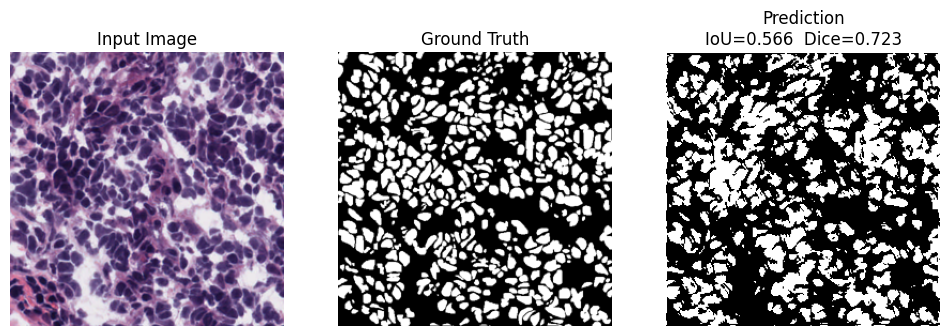

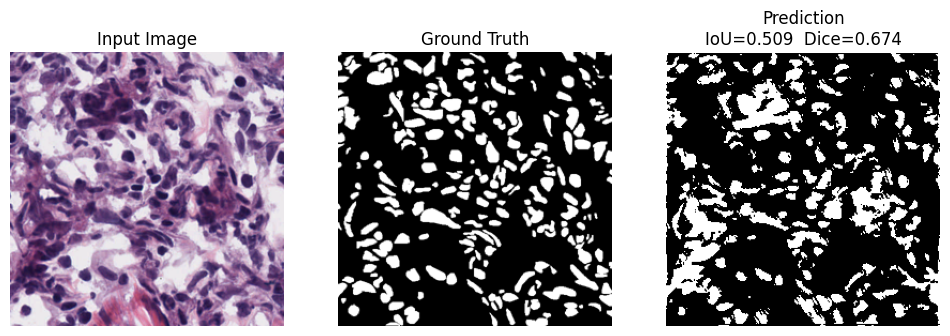

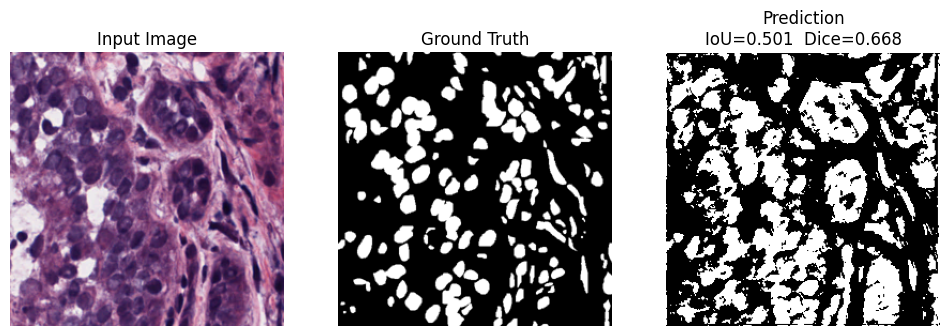

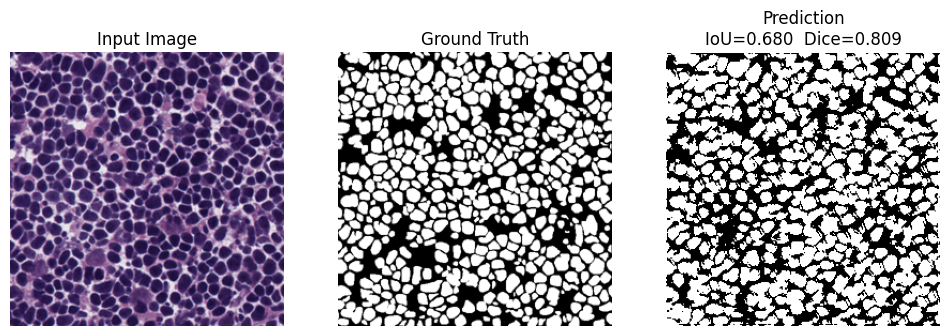

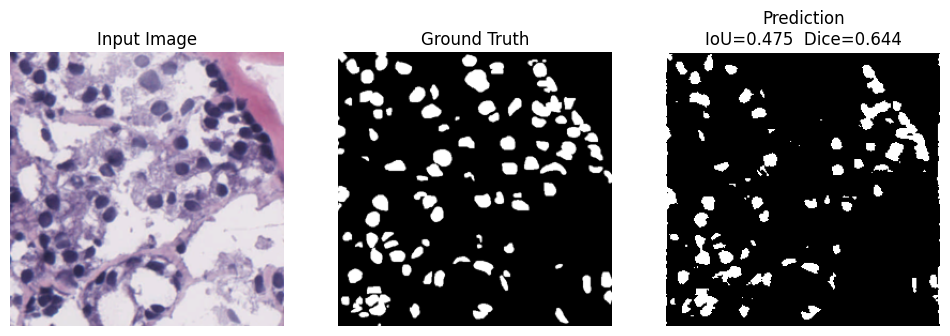

✅ Average IoU: 0.5463 | Average Dice: 0.7038


In [ ]:
import random

# pick a few random validation images
val_imgs = sorted([f for f in os.listdir(IMG_DIR) if f.endswith(('.png','.jpg','.tif'))])
samples = random.sample(val_imgs, min(5, len(val_imgs)))

ious, dices = [], []

for name in samples:
    # --- load image ---
    img = Image.open(os.path.join(IMG_DIR, name)).convert("RGB").resize((256,256))
    img_t = torch.tensor(np.array(img).transpose(2,0,1)/255.0, dtype=torch.float32).unsqueeze(0).to(device)

    # --- load mask (try .png or (1).png) ---
    base = os.path.splitext(name)[0]
    for cand in [f"{base}.png", f"{base} (1).png", f"{base}.tif", f"{base} (1).tif"]:
        mp = os.path.join(MASK_DIR, cand)
        if os.path.exists(mp):
            mask = Image.open(mp).convert("L").resize((256,256))
            break
    gt = np.array(mask)/255.0
    gt_t = torch.tensor(gt, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)

    # --- predict ---
    with torch.no_grad():
        sam_emb = torch.zeros_like(img_t[:, :1, :, :])     # dummy embedding
        pred = model(img_t, sam_emb).cpu().squeeze().numpy()

    # --- metrics ---
    i, d = iou_dice(pred, gt)
    ious.append(i); dices.append(d)

    # --- visualize ---
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.imshow(img); plt.title("Input Image"); plt.axis("off")
    plt.subplot(1,3,2); plt.imshow(gt, cmap='gray'); plt.title("Ground Truth"); plt.axis("off")
    plt.subplot(1,3,3); plt.imshow(pred>0.5, cmap='gray'); plt.title(f"Prediction\nIoU={i:.3f}  Dice={d:.3f}"); plt.axis("off")
    plt.show()

print(f"✅ Average IoU: {np.mean(ious):.4f} | Average Dice: {np.mean(dices):.4f}")
